## Experiments: Dropout and Optimization

Idongesit <br>
October 30th, 2026

This notebook tests how dropout and the optimizer affect the CNN-LSTM. Each experiment changes one parameter from the base model and compares the result on the validation set.

### How to Use This Notebook

- Build and run the base model first. Every experiment is compared with it, so it already covers the base value.
- Change one parameter at a time. Everything else stays at the base model.
- Before running an experiment, fill in the values you are testing, your hypothesis, why you chose those values, and the source that informed them.
- Judge results on validation accuracy and macro F1 only. The test set is saved for the final model.
- Fill in each results table, then the observations, insights and conclusion.

### Setup

In [3]:
import os

# Hide GPUs so everyone trains and times on CPU.
# Must run before importing TensorFlow; restart the kernel if it already was.
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

In [4]:
import copy as cp
import random
import time

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from IPython.display import display, HTML
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping, Callback
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam, SGD
from sklearn.metrics import f1_score, confusion_matrix

In [5]:
SEED = 8
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed()

In [6]:
DATA_ROOT       = '../DATA'
FEATURE_PATH    = DATA_ROOT + '/features'
EXP_DATA_PREFIX = 'resnet50_224_'   
LABEL_FILE      = 'splits.npz'

TRAIN      = 'train'
VALIDATION = 'val'
TEST       = 'test'


def load_data():
    features = {}
    labels   = {}

    label_data = np.load(f"{DATA_ROOT}/{LABEL_FILE}")

    for name in [TRAIN, VALIDATION, TEST]:
        # features are saved as float16 to save space, so cast back for training
        features[name] = np.load(f"{FEATURE_PATH}/{EXP_DATA_PREFIX}{name}.npy").astype('float32')[:, ::2]
        labels[name]   = label_data[f'y_{name}']

    return (features, labels)

X, y = load_data()

reports = []

for name in [TRAIN, VALIDATION, TEST]:
    print(name, X[name].shape, y[name].shape)

train (552, 16, 2048) (552,)
val (151, 16, 2048) (151,)
test (263, 16, 2048) (263,)


In [7]:
def config_to_html(conf):
    items = []
    for k, v in conf.items():
        if not isinstance(v, (int, float, str, tuple, list)):
            v = v.__name__
        items.append(f"{k}: {v}")
    return "<small>" + " | ".join(items) + "</small>"


def print_report(df):
    styled_df = (df.style
                 .format({'Val accuracy': '{:.4f}', 'Val macro F1': '{:.4f}',
                          'Latency (ms)': '{:.1f}', 'Train time (s)': '{:.1f}'})
                 # center everything except the long Parameters text
                 .set_properties(**{'text-align': 'center'})
                 .set_properties(subset=['Parameters'], **{'text-align': 'left', 'min-width': '420px'})
                 .set_table_styles([
                     {'selector': 'th', 'props': [('text-align', 'center'), ('font-weight', 'bold')]}
                 ]))
    try:
        styled_df = styled_df.hide_index()
    except AttributeError:
        styled_df = styled_df.hide(axis='index')

    display(HTML("<h4>Results</h4>"))
    display(styled_df)


def plot_training_history(history):
    _, axes = plt.subplots(1, 2, figsize=(12, 5))

    # left plot: accuracy
    ax = axes[0]
    ax.plot(history['accuracy'], label='Training Accuracy')
    ax.plot(history['val_accuracy'], label='Validation Accuracy')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend()

    # right plot: loss 
    ax = axes[1]
    ax.plot(history['loss'], label='Training Loss')
    ax.plot(history['val_loss'], label='Validation Loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()

    plt.tight_layout()
    plt.show()

In [8]:
class LatencyTracker(Callback):
    
    def on_train_begin(self, logs=None):
        # reset the counters at the start of every fit()
        self.epoch_times = []
        self.total_epochs = 0

    def on_epoch_begin(self, epoch, logs=None):
        # start the clock for this epoch
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        # stop the clock and store how long the epoch took
        duration = time.time() - self.epoch_start_time

        self.epoch_times.append(duration)
        self.total_epochs += 1

    @property
    def total_latency(self):
        # total training time across all epochs
        return sum(self.epoch_times)

In [9]:
def create_optimizer(params):
    if params['Optimizer'] == Adam:
        return Adam(learning_rate=params['Learning rate'])
    if params['Optimizer'] == SGD:
        # momentum 0.9 is the usual starting setup for SGD
        return SGD(learning_rate=params['Learning rate'], momentum=0.9)
    return None


def measure_prediction_latency(model, X_clips, n_clips=100):
    clips = tf.constant(X_clips[:n_clips])
    model(clips[:1], training=False)  

    start = time.time()
    for i in range(n_clips):
        model(clips[i:i + 1], training=False) 
    return (time.time() - start) / n_clips * 1000


def run_experiment(params, X, y, verbose=0, print_all=True):
    # free the memory used by earlier models so it doesn't build up across runs
    tf.keras.backend.clear_session()

    # reset every random seed so the same settings always give the same result
    set_seed()

    input_shape = X[TRAIN].shape[1:]  # (frames, feature size)
    rate        = params['Dropout rate']
    placement   = params['Dropout placement']   # 'after' (base), 'before', 'both' or 'internal'

    # create model: (dropout) -> recurrent layer -> (dropout) -> softmax output
    model = Sequential()
    model.add(Input(shape=input_shape))
    if placement in ('before', 'both'):
        model.add(Dropout(rate))              # dropout on the frame features
    # the LSTM's own dropout argument is only used for the 'internal' setting
    model.add(params['Recurrent layer'](params['Hidden units'],
                                        dropout=rate if placement == 'internal' else 0.0))
    if placement in ('after', 'both'):
        model.add(Dropout(rate))              # dropout after the LSTM (base model)
    model.add(Dense(params['Output'][0], activation=params['Output'][1]))

    # compile model
    model.compile(
        optimizer=create_optimizer(params),
        loss=params['Loss'],
        metrics=params['Metrics']
    )

    model.summary()

    # early stopping watches the validation loss and keeps the best weights
    early_stopping = EarlyStopping(monitor=params['Monitor'],
                                   patience=params['Patience'],
                                   restore_best_weights=params['Restore best weights'])

    # records how long each epoch takes
    latency_tracker = LatencyTracker()

    history = model.fit(X[TRAIN], y[TRAIN],
                        validation_data=(X[VALIDATION], y[VALIDATION]),
                        epochs=params['Epochs'],
                        batch_size=params['Batch size'],
                        callbacks=[early_stopping, latency_tracker],
                        verbose=verbose)

    # validation metrics for the report
    val_loss, val_accuracy = model.evaluate(X[VALIDATION], y[VALIDATION], verbose=0)
    y_val_pred = np.argmax(model.predict(X[VALIDATION], verbose=0), axis=1)  # predicted class per clip
    val_f1 = f1_score(y[VALIDATION], y_val_pred, average=params['F1 Average'])

    report = {
        'Val accuracy': round(val_accuracy, 4),
        'Val macro F1': round(val_f1, 4),
        'Epochs run': len(history.history['loss']),  # one loss value is stored per epoch
        'Params': model.count_params(),
        'Parameters': config_to_html(params),
        'Latency (ms)': round(measure_prediction_latency(model, X[VALIDATION]), 1),
        'Train time (s)': round(latency_tracker.total_latency, 1)
    }

    # add this run to the running results table
    report_ext = {
        'Run': params['Experiment Name'],
        'Setting': params['Setting']
    }
    report_ext.update(report)
    reports.append(report_ext)

    if print_all:
        print_report(pd.DataFrame(reports))
    else:
        print_report(pd.DataFrame([report]))
    plot_training_history(history.history)

### Base Model

| Parameter | Base model |
|---|---|
| Backbone | ResNet50 (frozen, ImageNet weights) |
| Input resolution | 224 px |
| Frames per clip | 16 |
| Recurrent layer type | LSTM |
| Hidden units | 256 |
| Number of recurrent layers | 1 |
| Dropout placement | After the LSTM |
| Dropout rate | 0.5 |
| Output | Dense(8, softmax) |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss | Sparse categorical cross-entropy |
| Batch size | 32 |
| Epochs | Up to 100, early stopping on val loss (patience 8, restore best weights) |
| Seed | 8 |

In [10]:
baseline_config = {}
baseline_config['Experiment Name'] = "base"
baseline_config['Setting'] = "-"

baseline_config['Recurrent layer']   = LSTM
baseline_config['Hidden units']      = 256
baseline_config['Dropout placement'] = "after"              # after the LSTM
baseline_config['Dropout rate']      = 0.5
baseline_config['Output']            = (8, "softmax")       # 8 exercise classes
baseline_config['Optimizer']         = Adam
baseline_config['Learning rate']     = 0.001
baseline_config['Loss']              = "sparse_categorical_crossentropy"
baseline_config['Metrics']           = ["accuracy"]
baseline_config['Batch size']        = 32
baseline_config['Epochs']            = 100                  # upper limit; early stopping ends it sooner
baseline_config['F1 Average']        = "macro"
baseline_config['Monitor']           = "val_loss"           # early stopping watches validation loss
baseline_config['Patience']          = 8
baseline_config['Restore best weights'] = True

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lstm (LSTM)                  (None, 256)               2360320   
_________________________________________________________________
dropout (Dropout)            (None, 256)               0         
_________________________________________________________________
dense (Dense)                (None, 8)                 2056      
Total params: 2,362,376
Trainable params: 2,362,376
Non-trainable params: 0
_________________________________________________________________
Train on 552 samples, validate on 151 samples
Epoch 1/100
552/552 [==============================] - 11s 19ms/sample - loss: 1.4295 - accuracy: 0.5254 - val_loss: 1.6904 - val_accuracy: 0.3510
Epoch 2/100
552/552 [==============================] - 6s 10ms/sample - loss: 0.5488 - accuracy: 0.8750 - val_loss: 1.5673 - val_accuracy: 0.4437
Epoch 3/100
552/552 [================

Val accuracy,Val macro F1,Epochs run,Params,Parameters,Latency (ms),Train time (s)
0.5033,0.5289,12,2362376,"Experiment Name: base | Setting: - | Recurrent layer: LSTM | Hidden units: 256 | Dropout placement: after | Dropout rate: 0.5 | Output: (8, 'softmax') | Optimizer: Adam | Learning rate: 0.001 | Loss: sparse_categorical_crossentropy | Metrics: ['accuracy'] | Batch size: 32 | Epochs: 100 | F1 Average: macro | Monitor: val_loss | Patience: 8 | Restore best weights: True",74.6,72.9


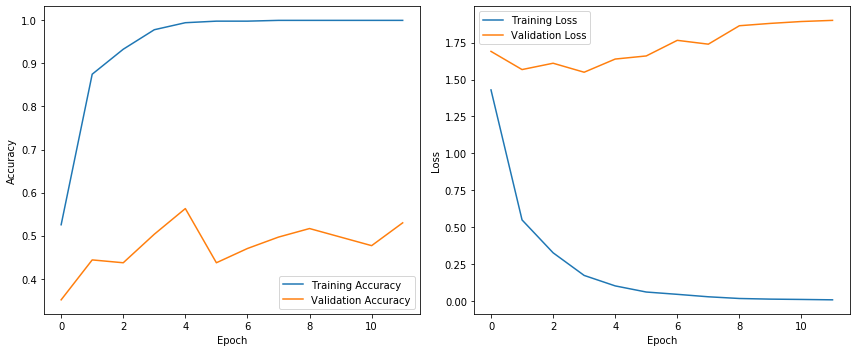

In [11]:
# Train and evaluate the base model: LSTM 256, dropout 0.5 after the LSTM, Adam 0.001
run_experiment(baseline_config, X, y, verbose=1, print_all=False)

#### Results

| Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|
| | | | | |

### Dropout Placement

| Parameter | Base model | Testing |
|---|---|---|
| Dropout placement | After the LSTM | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Dropout Rate

| Parameter | Base model | Testing |
|---|---|---|
| Dropout rate | 0.5 | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Optimizer and Learning Rate

| Parameter | Base model | Testing |
|---|---|---|
| Optimizer | Adam | |
| Learning rate | 0.001 | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Summary

| Experiment | Best value | Carry forward? | Reason |
|---|---|---|---|
| Dropout Placement | | | |
| Dropout Rate | | | |
| Optimizer and Learning Rate | | | |

#### Overall Conclusions

_What should the final model use, and what did these experiments show about the problem?_